In [186]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

In [187]:
arm_length = 600 # mm
support_x = 100 # mm
support_y = 100 # mm

spring_dist = 300 # mm from root to spring mount


end_weight = 10 # N

Spring rate: 0.3509326758898315
Length offset: 5.000799764788914
Max joint torque: 1309.3096117433279


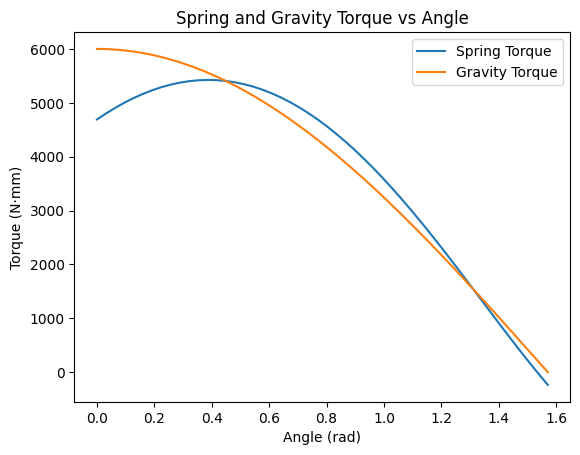

In [188]:
def calculate_spring_torque(spring_rate, length_offset, arm_length, support_x, support_y, spring_dist, end_weight):
    spring_rest_length = np.sqrt(
        (spring_dist * np.cos(np.pi/2) + support_x)**2 +
        (spring_dist * np.sin(np.pi/2) - support_y)**2
        ) + length_offset # mm

    angles = np.linspace(0, np.pi/2)

    gravity_torque = arm_length * np.cos(angles) * end_weight

    f_dx = spring_dist * np.cos(angles) + support_x
    f_dy = spring_dist * np.sin(angles) - support_y
    spring_force = -spring_rate * (np.sqrt(f_dx**2 + f_dy**2) - spring_rest_length)

    fx = f_dx / np.sqrt(f_dx**2 + f_dy**2) * spring_force
    fy = f_dy / np.sqrt(f_dx**2 + f_dy**2) * spring_force

    dx = spring_dist * np.cos(angles)
    dy = spring_dist * np.sin(angles)

    spring_torque = dx * fy - dy * fx

    return angles, spring_torque, gravity_torque

def get_spring_error(params):
    spring_rate, length_offset = params
    angles, spring_torque, gravity_torque = calculate_spring_torque(spring_rate, length_offset, arm_length, support_x, support_y, spring_dist, end_weight)
    
    return np.max(abs(spring_torque - gravity_torque))*0.2 + np.sum(np.abs(spring_torque - gravity_torque)*np.diff(angles)[0])

spring_rate, length_offset = least_squares(get_spring_error, (0.5, 5)).x
print("Spring rate:", spring_rate)
print("Length offset:", length_offset)

angles, spring_torque, gravity_torque = calculate_spring_torque(spring_rate, length_offset, arm_length, support_x, support_y, spring_dist, end_weight)
print("Max joint torque:", np.max(abs(spring_torque - gravity_torque)))

fig, ax = plt.subplots()
ax.plot(angles, spring_torque, label='Spring Torque')
ax.plot(angles, gravity_torque, label='Gravity Torque')
ax.set_xlabel('Angle (rad)')
ax.set_ylabel('Torque (N·mm)')
ax.set_title('Spring and Gravity Torque vs Angle')
ax.legend()
plt.show()